# 01 — Analyse exploratoire (EDA)
Exploration du dataset de leads TAC-TIC avant modélisation.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))  # racine ml/ -> import src.*
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.features.pipeline import load_dataset
df = load_dataset()
df.head()

,id,source,sentiment,urgency,intention,product_service,location,language,estimated_value,interaction_count,message,status,priority,lead_score,customer_status,created_at,last_contact_at,converted
0,lead_000000,social_media,positive,low,purchase-ready,CRM Workflow Automation,"Sfax, Tunisia",fr,13974.93,2,"Nous voulons démarrer rapidement, pouvez-vous ...",new,low,51,lead,2025-08-19T03:00:00,2025-09-13T03:00:00,0
1,lead_000001,web,neutral,low,purchase-ready,CRM Workflow Automation,"Bizerte, Tunisia",fr,18626.88,3,"Nous voulons démarrer rapidement, pouvez-vous ...",new,low,75,lead,2025-07-22T06:00:00,2025-08-09T06:00:00,0
2,lead_000002,event,positive,medium,purchase-ready,AI CRM Automation,"Monastir, Tunisia",fr,16410.82,4,"Budget validé en interne, on souhaite signer c...",hot,high,96,active_customer,2026-02-20T17:00:00,2026-03-02T17:00:00,1
3,lead_000003,organic_search,neutral,high,information-gathering,CRM Workflow Automation,"Bizerte, Tunisia",fr,9288.58,3,"Pas pressé, je collecte juste des informations...",cold,high,47,lead,2026-03-12T03:00:00,2026-04-05T03:00:00,0
4,lead_000004,social_media,negative,medium,information-gathering,AI CRM Automation,"Ariana, Tunisia",en,10021.91,3,Just gathering some information about what you...,cold,medium,13,prospect,2025-12-29T00:00:00,2026-01-21T00:00:00,0


## Shape, types et valeurs manquantes

In [2]:
print('Shape:', df.shape)
print(df.dtypes)
print('\nValeurs manquantes:')
print(df.isna().sum())

Shape: (5000, 18)
id                    object
source                object
sentiment             object
urgency               object
intention             object
product_service       object
location              object
language              object
estimated_value      float64
interaction_count      int64
message               object
status                object
priority              object
lead_score             int64
customer_status       object
created_at            object
last_contact_at       object
converted              int64
dtype: object

Valeurs manquantes:
id                     0
source                 0
sentiment              0
urgency                0
intention              0
product_service        0
location               0
language               0
estimated_value        0
interaction_count      0
message                0
status                 0
priority               0
lead_score             0
customer_status        0
created_at             0
last_contact_at      895


## Distribution de la cible `converted`

converted
0    0.586
1    0.414
Name: proportion, dtype: float64


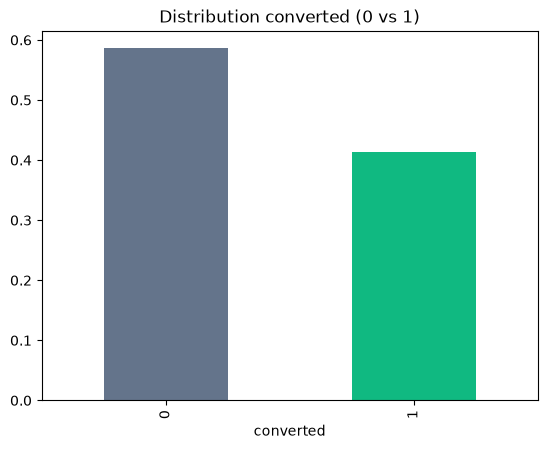

In [3]:
dist = df['converted'].value_counts(normalize=True).round(3)
print(dist)
dist.plot(kind='bar', color=['#64748b','#10b981'])
plt.title('Distribution converted (0 vs 1)'); plt.show()

## Taux de conversion par source

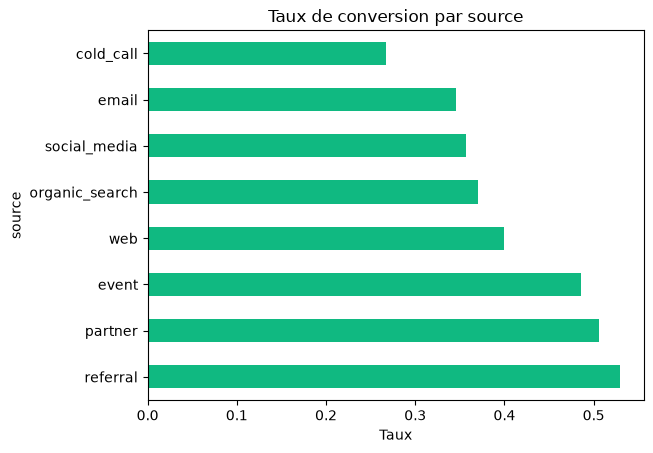

source
referral          0.529540
partner           0.505848
event             0.485411
web               0.399687
organic_search    0.370763
social_media      0.357480
email             0.345930
cold_call         0.266892
Name: converted, dtype: float64

In [4]:
by_source = df.groupby('source')['converted'].mean().sort_values(ascending=False)
by_source.plot(kind='barh', color='#10b981')
plt.title('Taux de conversion par source'); plt.xlabel('Taux'); plt.show()
by_source

## Taux de conversion par sentiment

In [5]:
df.groupby('sentiment')['converted'].mean().round(3)

sentiment
negative    0.246
neutral     0.384
positive    0.541
Name: converted, dtype: float64

## Taux de conversion par urgence

In [6]:
df.groupby('urgency')['converted'].mean().round(3)

urgency
high      0.562
low       0.278
medium    0.438
Name: converted, dtype: float64

## Corrélation des features numériques avec converted

In [7]:
num = df[['estimated_value','interaction_count','lead_score','converted']]
num.corr()['converted'].sort_values(ascending=False)

converted            1.000000
lead_score           0.325199
interaction_count    0.178393
estimated_value      0.005560
Name: converted, dtype: float64

## Top 5 messages : leads convertis vs non convertis

In [8]:
print('--- CONVERTIS ---')
for m in df[df.converted==1]['message'].head(5): print(' •', m)
print('\n--- NON CONVERTIS ---')
for m in df[df.converted==0]['message'].head(5): print(' •', m)

--- CONVERTIS ---
 • Budget validé en interne, on souhaite signer ce mois-ci.
 • Pas pressé, je collecte juste des informations pour plus tard.
 • Nous voulons démarrer rapidement, pouvez-vous m'envoyer un devis ?
 • Ready to buy, what are the next steps for onboarding?
 • Prêt à acheter, quelles sont les prochaines étapes pour la mise en place ?

--- NON CONVERTIS ---
 • Nous voulons démarrer rapidement, pouvez-vous m'envoyer un devis ?
 • Nous voulons démarrer rapidement, pouvez-vous m'envoyer un devis ?
 • Pas pressé, je collecte juste des informations pour plus tard.
 • Just gathering some information about what you offer.
 • Pas pressé, je collecte juste des informations pour plus tard.


## Conclusions EDA
- Dataset équilibré (~41% de conversion).
- `intention`, `sentiment`, `urgency` et `source` sont les leviers les plus discriminants.
- `lead_score` (LLM) est corrélé mais imparfait -> baseline à battre.
- Les colonnes dérivées du résultat (status, priority, customer_status, lead_score) sont exclues des features pour éviter toute fuite.